# Лабораторная работа №2: Продвинутая инженерия признаков и отбор

**Вариант №1** · датасет **Titanic** (`seaborn`) · задача **бинарная классификация** (таргет `survived`)

Что требуется по варианту:

1. **Импутация пропусков** — сравнить `SimpleImputer` (медиана), `KNNImputer`, `IterativeImputer`
   внутри `Pipeline` с 5-фолдовой кросс-валидацией (метрика ROC-AUC).
2. **Детекция выбросов** — `IsolationForest` и **кастомный трансформер**, удаляющий выбросы
   *только из обучающей выборки*, встроенный в пайплайн (`imblearn.pipeline.Pipeline`).
3. **Отбор признаков** — минимум два метода из разных групп: **Mutual Information** (фильтр)
   и **Lasso** (встроенный).

Порядок работы: загрузка и «загрязнение» данных → фиксация отложенного теста → генерация признаков →
сравнение импутеров → детекция выбросов → отбор признаков → финальный пайплайн с подбором
гиперпараметров → оценка на тесте и выводы.

## 1. Импорты и настройки

In [1]:
%matplotlib inline
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import SelectFromModel, SelectKBest, mutual_info_classif
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LassoCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Корень проекта ищем по наличию .git — ноутбук можно запускать из любой папки
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / '.git').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW_DIR = PROJECT_ROOT / 'src' / 'data' / 'raw'
MODELS_DIR = PROJECT_ROOT / 'src' / 'models'
REPORTS_DIR = PROJECT_ROOT / 'src' / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
for _d in (MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Сохранить текущий рисунок в src/reports/figures и показать его в ноутбуке."""
    path = FIGURES_DIR / f'{name}.png'
    plt.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Рисунок сохранён:', path.relative_to(PROJECT_ROOT))


print('PROJECT_ROOT:', PROJECT_ROOT)
print('sklearn', __import__('sklearn').__version__,
      '| pandas', pd.__version__,
      '| numpy', np.__version__)

PROJECT_ROOT: C:\OmSTU\Prodvinutie_metodi_7_semester\Pract_exercise
sklearn 1.9.1 | pandas 3.0.6 | numpy 2.5.3


## 2. Загрузка данных (файл уже лежит в `data/raw` под DVC)

Titanic уже сохранён в `src/data/raw/titanic.csv` и версионируется DVC (добавлен в ЛР1), поэтому
повторно из сети не выгружаем — читаем файл напрямую. Требование «загрузите датасет, сохраните
в `data/raw`» выполнено: файл лежит в `data/raw`, а его версия зафиксирована `.dvc`-файлом
(`dvc status` → data up to date).

In [2]:
DATA_PATH = DATA_RAW_DIR / 'titanic.csv'
titanic = pd.read_csv(DATA_PATH)
print('Источник (под DVC):', DATA_PATH.relative_to(PROJECT_ROOT))
print('Форма датасета:', titanic.shape)
titanic.head()

Источник (под DVC): src\data\raw\titanic.csv
Форма датасета: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2.1. Пропуски и выбросы: что уже есть в данных

Отдельно «загрязнять» датасет не нужно — условия задания («**если** пропусков нет…», «**если**
выбросов нет…») не выполняются, всё необходимое в данных уже присутствует.

**Пропуски (двух разных механизмов).**

- `age` — 252 пропуска (28.3%): 177 родных пропусков Titanic (**MAR**: связаны с наблюдаемым
  `pclass` — у пассажиров с пропущенным возрастом средний класс 2.45 против 2.25) плюс 75 пропусков,
  внесённых ещё в ЛР1 механизмом **MCAR** (10% случайных значений);
- `fare` — 89 пропусков (10.0%), внесены в ЛР1 механизмом **MCAR**;
- `deck` — 688 (77.2%), `embarked`/`embark_town` — 2: родные пропуски.

Итого: требуемые заданием **10–15% случайных (MCAR) пропусков в числовых колонках** уже есть —
это `age` и `fare` из ЛР1. MAR-компонент в `age` дополнительно оставлен, чтобы датасет вёл себя
реалистично. Колонка `deck` почти полностью пустая, поэтому ниже пропуск в ней превращаем
в явную категорию `Unknown` (факт отсутствия каюты информативен).

**Выбросы тоже есть.** `fare` — сильно скошенная величина: медиана 14.45, 75-й процентиль 31.0,
а максимум 512.33 (дорогие каюты 1-го класса). IsolationForest находит такие объекты без
искусственного «домножения» — это и проверяется в разделе 6.

In [3]:
missing = titanic.isna().sum()
print('Пропуски в датасете (%d строк):' % len(titanic))
print(pd.DataFrame({'пропусков': missing[missing > 0],
                    'доля, %': (100 * missing[missing > 0] / len(titanic)).round(1)}).to_string())

age_na = titanic['age'].isna()
fam_size = titanic[['sibsp', 'parch']].sum(axis=1) + 1
print('\nПроверка механизма пропусков в age (MAR — связаны с наблюдаемыми признаками):')
print('  средний pclass при age=NaN: %.2f | при заполненном age: %.2f'
      % (titanic.loc[age_na, 'pclass'].mean(), titanic.loc[~age_na, 'pclass'].mean()))
print('  доля выживших при age=NaN: %.3f | при заполненном age: %.3f'
      % (titanic.loc[age_na, 'survived'].mean(), titanic.loc[~age_na, 'survived'].mean()))
print('  средний размер семьи при age=NaN: %.2f | при заполненном age: %.2f'
      % (fam_size[age_na].mean(), fam_size[~age_na].mean()))
print('\nИтого: MCAR-пропуски задания (10–15% в числовых колонках) — это age и fare,')
print('внесённые в ЛР1; MAR-пропуски age и почти пустая deck оставлены как есть.')

Пропуски в датасете (891 строк):
             пропусков  доля, %
age                252     28.3
fare                89     10.0
embarked             2      0.2
deck               688     77.2
embark_town          2      0.2

Проверка механизма пропусков в age (MAR — связаны с наблюдаемыми признаками):
  средний pclass при age=NaN: 2.45 | при заполненном age: 2.25
  доля выживших при age=NaN: 0.333 | при заполненном age: 0.404
  средний размер семьи при age=NaN: 1.81 | при заполненном age: 1.94

Итого: MCAR-пропуски задания (10–15% в числовых колонках) — это age и fare,
внесённые в ЛР1; MAR-пропуски age и почти пустая deck оставлены как есть.


In [4]:
print('Мини-аудит числовых колонок (именно на них работают импутеры и детектор выбросов):')
titanic[['age', 'sibsp', 'parch', 'fare']].describe().round(2)

Мини-аудит числовых колонок (именно на них работают импутеры и детектор выбросов):


,age,sibsp,parch,fare
count,639.00,891.00,891.00,802.00
mean,29.75,0.52,0.38,32.59
std,14.61,1.10,0.81,50.94
min,0.42,0.00,0.00,0.00
25%,21.00,0.00,0.00,7.90
50%,28.00,0.00,0.00,14.45
75%,38.50,1.00,0.00,31.00
max,80.00,8.00,6.00,512.33


## 3. Отложенная тестовая выборка

Тест отрезаем **один раз и навсегда** ещё до импутации, детекции выбросов и отбора признаков:
иначе любые «подглядывания» (обучение импутера/селектора на всём датасете) завысили бы качество.
Колонку `alive` убираем — это текстовая копия таргета `survived` (прямая утечка). Сплит
стратифицирован по таргету, 75/25, `random_state=42`.

In [5]:
TARGET = 'survived'
data = titanic.drop(columns=['alive'])  # alive — текстовая копия таргета (утечка)

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
print('Train: %s | Test: %s' % (X_train.shape, X_test.shape))
print('Доля выживших — train: %.3f | test: %.3f | весь датасет: %.3f'
      % (y_train.mean(), y_test.mean(), y.mean()))
print('Тестовая выборка не используется до раздела 8.')

Train: (668, 13) | Test: (223, 13)
Доля выживших — train: 0.383 | test: 0.386 | весь датасет: 0.384
Тестовая выборка не используется до раздела 8.


## 4. Генерация признаков: кастомный трансформер

Датасет **одиночный** (одна плоская таблица), связей между таблицами нет, поэтому `Featuretools`
с `EntitySet`/DFS здесь неприменим — по условию задания используем **ручные признаки**
и добавляем `PolynomialFeatures` (см. раздел 7).

Трансформер `TitanicFeatureAdder` создаёт осмысленные для Titanic признаки:

| признак | смысл |
|---|---|
| `family_size` | `sibsp + parch + 1` — размер семьи на борту |
| `is_alone` | путешествует один (числовой 0/1) |
| `fare_per_person` | `fare / family_size` — цена билета на человека |
| `sex_class` | взаимодействие «пол × класс» (`male_Third`), сильный предиктор выживания |
| `deck` | палуба каюты; пропуск превращаем в явную категорию `Unknown` (факт отсутствия каюты информативен) |

Важно: в **seaborn**-версии датасета нет колонок `name`, `ticket`, `cabin` (они есть только в сыром
Kaggle-файле), поэтому признаки вроде `title`/`ticket_prefix` здесь недоступны — используем то,
что даёт источник данных.

Трансформер наследуется от `BaseEstimator` и `TransformerMixin` (для корректной работы внутри
`Pipeline` и `clone` и чтобы `sklearn` мог использовать быстрый путь `fit_transform`),
не изменяет таргет и не удаляет строки, поэтому безопасен на любом этапе пайплайна.

In [6]:
class TitanicFeatureAdder(BaseEstimator, TransformerMixin):
    """Ручная генерация признаков для одиночной таблицы Titanic (версия seaborn)."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        # размер семьи и признак «путешествует один»
        X['family_size'] = X['sibsp'].fillna(0) + X['parch'].fillna(0) + 1
        X['is_alone'] = (X['family_size'] == 1).astype(int)
        # цена билета на человека (большая семья в одном билете — дешевле на человека)
        X['fare_per_person'] = X['fare'] / X['family_size']
        # взаимодействие «пол × класс» — компактная и очень сильная комбинация
        X['sex_class'] = X['sex'].astype(str) + '_' + X['class'].astype(str)
        # палуба каюты: пропуск превращаем в отдельную категорию Unknown
        X['deck'] = X['deck'].astype(str).where(X['deck'].notna(), 'Unknown')
        return X


demo = TitanicFeatureAdder().fit_transform(X_train.head(5))
new_cols = [c for c in demo.columns if c not in X_train.columns]
print('Добавленные признаки:', new_cols)
demo[new_cols].head()

Добавленные признаки: ['family_size', 'is_alone', 'fare_per_person', 'sex_class']


,family_size,is_alone,fare_per_person,sex_class
486,2,0,NaN,female_First
238,1,1,10.500000,male_Second
722,1,1,13.000000,male_Second
184,3,0,7.341667,female_Third
56,1,1,10.500000,female_Second


## 5. Сравнение методов импутации пропусков

Схема эксперимента — единый пайплайн на `imblearn.pipeline.Pipeline`:

```
TitanicFeatureAdder -> ColumnTransformer -> RandomForestClassifier
```

Числовая ветка `ColumnTransformer` устроена так (порядок слоёв важен):

1. `StandardScaler` **до импутера** — `KNNImputer` и `IterativeImputer` работают с расстояниями
   и линейными моделями, а без масштабирования `fare` (0–512) полностью подавляет `age` (0–80)
   и `sibsp`/`parch` (0–8). `StandardScaler` корректно игнорирует `NaN` при обучении и сохраняет их при `transform`;
2. `imputer` — сравниваемый метод (`SimpleImputer(strategy='median')` / `KNNImputer(k=5)` / `IterativeImputer`);
3. `PolynomialFeatures(degree=2)` — генерация степеней и взаимодействий (раздел 7);
4. `StandardScaler` — масштабирование уже заполненных значений перед подачей в модель.

Категориальная ветка: `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore',
sparse_output=False)`. One-hot отдаём **плотной** матрицей: датасет маленький, а `IsolationForest`,
`mutual_info_classif`, `Lasso` и `PCA` работают с плотными данными предсказуемее.

Качество каждого импутера — `cross_val_score` c `StratifiedKFold(5)`, метрика **ROC-AUC**
(классы несбалансированы ~38/62, поэтому accuracy менее информативна).

In [7]:
NUM_COLS = ['pclass', 'age', 'sibsp', 'parch', 'fare',
            'family_size', 'fare_per_person', 'is_alone']
CAT_COLS = ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'sex_class']


def make_preprocessor(imputer, use_poly=True):
    """ColumnTransformer: масштаб -> импутация -> (полином) -> масштаб | мода + OHE."""
    num_steps = [('scale_before_impute', StandardScaler()), ('imputer', clone(imputer))]
    if use_poly:
        num_steps.append(('poly', PolynomialFeatures(degree=2, include_bias=False)))
    num_steps.append(('scale_after', StandardScaler()))

    return ColumnTransformer(transformers=[
        ('num', Pipeline(num_steps), NUM_COLS),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), CAT_COLS),
    ])


def make_model_pipeline(imputer, use_poly=True, selector='passthrough', outliers=None,
                        n_estimators=300, max_depth=8, min_samples_leaf=1):
    """Полный конвейер: признаки -> препроцессинг -> [выбросы] -> [отбор] -> модель.

    Шаг удаления выбросов добавляется, только если задан `outliers`
    (класс OutlierDropper определён в разделе 6).
    """
    steps = [
        ('features', TitanicFeatureAdder()),
        ('prep', make_preprocessor(imputer, use_poly=use_poly)),
    ]
    if outliers is not None:
        steps.append(('outliers', OutlierDropper(contamination=outliers, random_state=SEED)))
    if selector != 'passthrough':
        steps.append(('select', selector))
    steps.append(('model', RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                                  min_samples_leaf=min_samples_leaf,
                                                  random_state=SEED, n_jobs=-1)))
    return ImbPipeline(steps)


def cv_roc_auc(pipeline, X_data=X_train, y_data=y_train):
    """ROC-AUC по 5-фолдовой стратифицированной кросс-валидации (фолды одни и те же)."""
    scores = cross_val_score(pipeline, X_data, y_data, cv=CV, scoring='roc_auc', n_jobs=1)
    return scores.mean(), scores.std()


CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(make_preprocessor(SimpleImputer(strategy='median')))

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scale_before_impute',
                                                  StandardScaler()),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('poly',
                                                  PolynomialFeatures(include_bias=False)),
                                                 ('scale_after',
                                                  StandardScaler())]),
                                 ['pclass', 'age', 'sibsp', 'parch', 'fare',
                                  'family_size', 'fare_per_person',
                                  'is_alone']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
 

In [8]:
IMPUTERS = {
    'SimpleImputer (медиана)': SimpleImputer(strategy='median'),
    'KNNImputer (k=5)': KNNImputer(n_neighbors=5),
    'IterativeImputer': IterativeImputer(random_state=SEED, max_iter=10),
}

imputer_rows = []
for name, imputer in IMPUTERS.items():
    mean_auc, std_auc = cv_roc_auc(make_model_pipeline(imputer))
    imputer_rows.append({'Метод импутации': name, 'ROC-AUC (mean)': mean_auc, 'std': std_auc})
    print('%-24s ROC-AUC = %.4f ± %.4f' % (name, mean_auc, std_auc))

imputer_results = (pd.DataFrame(imputer_rows)
                   .sort_values('ROC-AUC (mean)', ascending=False)
                   .reset_index(drop=True))
print('\nЛучший метод импутации:', imputer_results.loc[0, 'Метод импутации'])
imputer_results.round(4)

SimpleImputer (медиана)  ROC-AUC = 0.8543 ± 0.0147


KNNImputer (k=5)         ROC-AUC = 0.8625 ± 0.0172


IterativeImputer         ROC-AUC = 0.8544 ± 0.0154

Лучший метод импутации: KNNImputer (k=5)


,Метод импутации,ROC-AUC (mean),std
0,KNNImputer (k=5),0.8625,0.0172
1,IterativeImputer,0.8544,0.0154
2,SimpleImputer (медиана),0.8543,0.0147


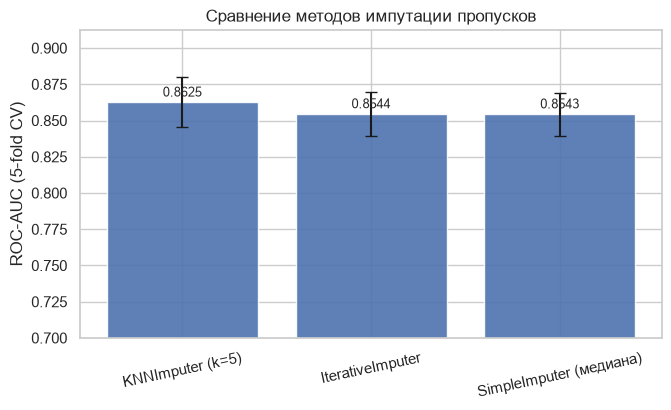

Рисунок сохранён: src\reports\figures\lab2_imputers_cv.png


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(imputer_results['Метод импутации'], imputer_results['ROC-AUC (mean)'],
       yerr=imputer_results['std'], capsize=4, color='#4C72B0', alpha=.9)
ax.set_ylabel('ROC-AUC (5-fold CV)')
ax.set_ylim(0.7, imputer_results['ROC-AUC (mean)'].max() + 0.05)
ax.set_title('Сравнение методов импутации пропусков')
for i, value in enumerate(imputer_results['ROC-AUC (mean)']):
    ax.text(i, value + 0.004, '%.4f' % value, ha='center', fontsize=9)
plt.xticks(rotation=12)
save_fig('lab2_imputers_cv')

### 5.1. Распределение значений до и после импутации

Проверяем не только метрику, но и *физику* заполнения: как импутеры меняют распределение
колонок `age` и `fare`. Импутация выполняется в масштабированных величинах (как в пайплайне),
затем значения возвращаются в исходные единицы через `inverse_transform`, чтобы графики
и статистики были интерпретируемы.

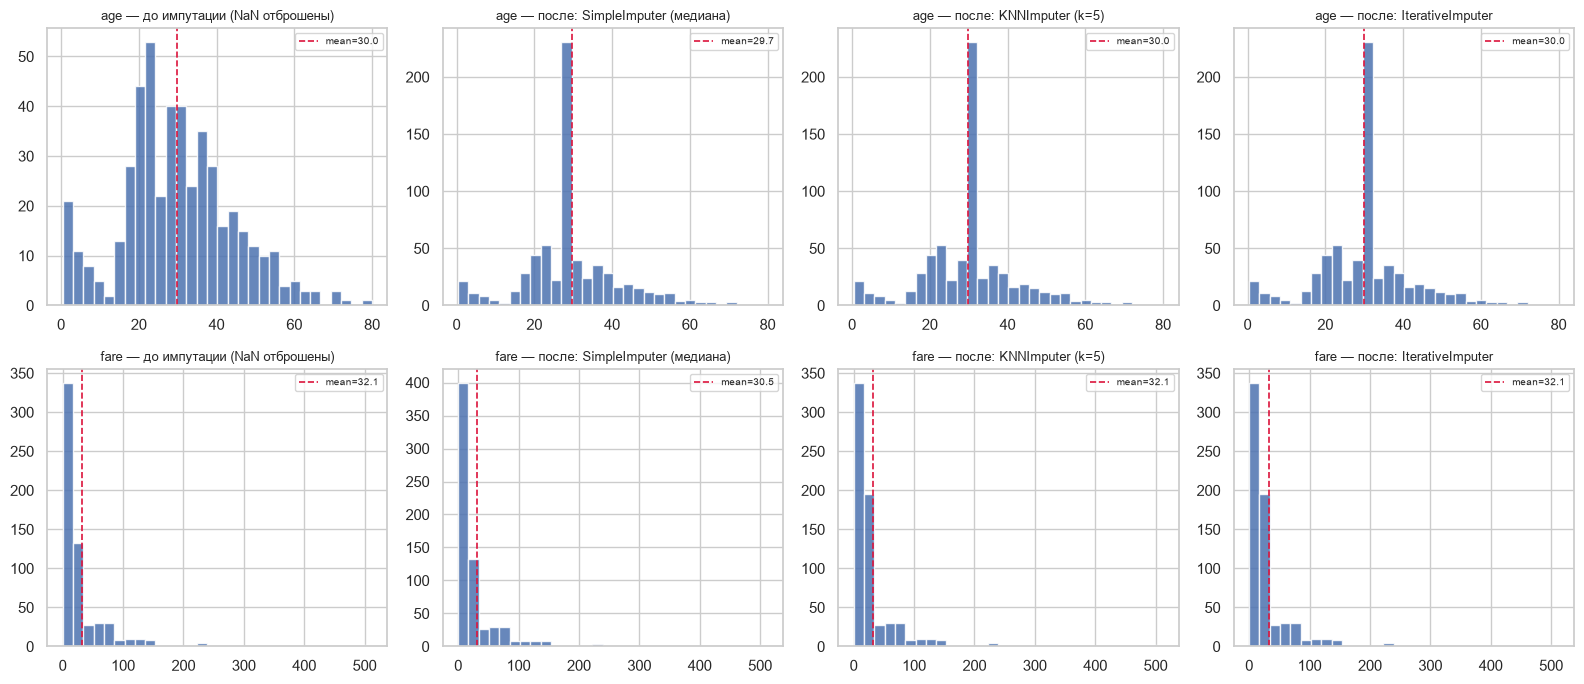

Рисунок сохранён: src\reports\figures\lab2_imputation_distributions.png


In [10]:
def impute_back(imputer, frame):
    """Обучает 'scaler -> imputer' на кадре и возвращает значения в исходных единицах."""
    scaler = StandardScaler().fit(frame)
    fitted = clone(imputer).fit(scaler.transform(frame))
    return pd.DataFrame(scaler.inverse_transform(fitted.transform(scaler.transform(frame))),
                        columns=frame.columns, index=frame.index)


HIST_COLS = ['age', 'fare']
fig, axes = plt.subplots(len(HIST_COLS), 4, figsize=(16, 7))
for row, col in enumerate(HIST_COLS):
    variants = {'до импутации (NaN отброшены)': X_train[col]}
    for name, imputer in IMPUTERS.items():
        variants['после: ' + name] = impute_back(imputer, X_train[[col]])[col]
    for k, (title, series) in enumerate(variants.items()):
        ax = axes[row, k]
        ax.hist(series.dropna(), bins=30, color='#4C72B0', alpha=.85, edgecolor='white')
        ax.axvline(series.mean(), color='crimson', ls='--', lw=1.2,
                   label='mean=%.1f' % series.mean())
        ax.set_title('%s — %s' % (col, title), fontsize=9)
        ax.legend(fontsize=7)
plt.tight_layout()
save_fig('lab2_imputation_distributions')

In [11]:
stats = {'до импутации': X_train['fare'].describe()[['mean', 'std', '50%']]}
for name, imputer in IMPUTERS.items():
    filled = impute_back(imputer, X_train[['fare']])['fare']
    stats[name] = filled.describe()[['mean', 'std', '50%']]
fare_stats = pd.DataFrame(stats).T
fare_stats.columns = ['mean', 'std', 'median']
print('Статистики fare до и после импутации (обратите внимание на std у KNN/Iterative):')
fare_stats.round(2)

Статистики fare до и после импутации (обратите внимание на std у KNN/Iterative):


,mean,std,median
до импутации,32.15,49.28,14.43
SimpleImputer (медиана),30.50,47.22,14.43
KNNImputer (k=5),32.15,46.94,16.05
IterativeImputer,32.15,46.94,16.05


## 6. Детекция выбросов: IsolationForest + визуализация через PCA

`IsolationForest` ищет аномалии, которые «изолируются» за малое число разбиений — он не требует
меток и работает с многомерным пространством. Применяем его к **преобразованным** обучающим данным
(масштабированные числовые + one-hot), потому что аномальность определяется всей комбинацией признаков.

Параметр `contamination=0.05` — ожидаемая доля аномалий (5% ≈ 33 строки из ~668).
Для визуализации снижаем размерность до 2 компонент методом **PCA** и раскрашиваем точки по метке:
«нормальные» синие, выбросы — красные крестики.

In [12]:
X_train_features = TitanicFeatureAdder().fit_transform(X_train)
preprocessor_ref = make_preprocessor(KNNImputer(n_neighbors=5)).fit(X_train_features)
X_train_prepared = preprocessor_ref.transform(X_train_features)
print('Размерность после препроцессинга:', X_train_prepared.shape)

iso_forest = IsolationForest(contamination=0.05, random_state=SEED, n_jobs=-1)
outlier_labels = iso_forest.fit_predict(X_train_prepared)
n_out = int((outlier_labels == -1).sum())
print('IsolationForest отметил выбросов: %d из %d (%.1f%%)'
      % (n_out, len(outlier_labels), 100 * n_out / len(outlier_labels)))

fare_by_label = pd.DataFrame({'fare': X_train_features['fare'].to_numpy(),
                              'outlier': outlier_labels})
print('\nСтатистика fare: выбросы (label = -1) против остальных:')
print(fare_by_label.groupby('outlier')['fare'].describe().round(2).to_string())

fare_p99 = X_train_features['fare'].quantile(0.99)
print('\n99-й процентиль fare: %.1f | выше него среди помеченных: %.2f'
      % (fare_p99, X_train_features.loc[outlier_labels == -1, 'fare'].gt(fare_p99).mean()))
print('Средняя стоимость билета у помеченных: %.1f против %.1f у остальных'
      % (X_train_features.loc[outlier_labels == -1, 'fare'].mean(),
         X_train_features.loc[outlier_labels == 1, 'fare'].mean()))

Размерность после препроцессинга: (668, 71)


IsolationForest отметил выбросов: 34 из 668 (5.1%)

Статистика fare: выбросы (label = -1) против остальных:
         count    mean     std   min    25%     50%     75%     max
outlier                                                            
-1        33.0  144.62  129.47  7.92  31.39  133.65  227.52  512.33
 1       573.0   25.67   29.32  0.00   7.90   13.00   27.75  164.87

99-й процентиль fare: 227.5 | выше него среди помеченных: 0.18
Средняя стоимость билета у помеченных: 144.6 против 25.7 у остальных


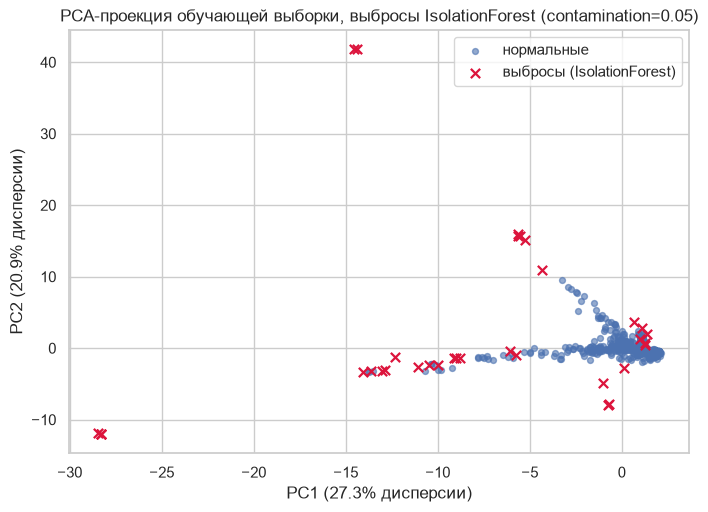

Рисунок сохранён: src\reports\figures\lab2_isolation_forest_pca.png


In [13]:
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_train_prepared)

fig, ax = plt.subplots(figsize=(8, 5.5))
inliers, outliers = coords[outlier_labels == 1], coords[outlier_labels == -1]
ax.scatter(inliers[:, 0], inliers[:, 1], s=18, c='#4C72B0', alpha=.6, label='нормальные')
ax.scatter(outliers[:, 0], outliers[:, 1], s=45, c='crimson', marker='x', lw=1.6,
           label='выбросы (IsolationForest)')
ax.set_xlabel('PC1 (%.1f%% дисперсии)' % (100 * pca.explained_variance_ratio_[0]))
ax.set_ylabel('PC2 (%.1f%% дисперсии)' % (100 * pca.explained_variance_ratio_[1]))
ax.set_title('PCA-проекция обучающей выборки, выбросы IsolationForest (contamination=0.05)')
ax.legend()
save_fig('lab2_isolation_forest_pca')

### 6.1. Кастомный трансформер `OutlierDropper` (удаляет выбросы только из train)

Требование задания: удалять выбросы **только из обучающей выборки**, не трогая тестовую.
Тонкость: удаление строк меняет и `X`, и `y`, а обычный `sklearn.pipeline.Pipeline` прокидывает
между шагами только `X`. Поэтому используется **`imblearn.pipeline.Pipeline`**, который умеет
работать с «sampler»-шагами — объектами с методом `fit_resample(X, y)`.

`OutlierDropper` реализован именно как sampler:

* есть `fit_resample(X, y)` → вызывается внутри `Pipeline.fit` для обучающих фолдов CV и удаляет
  строки-выбросы **вместе с их метками**;
* **нет** метода `transform` → на этапе `predict`/`transform` `imblearn.pipeline.Pipeline`
  полностью пропускает этот шаг (он фильтрует train-only шаги), поэтому тестовые объекты
  никогда не удаляются;
* есть вспомогательный `fit`, чтобы можно было посмотреть найденные выбросы вручную.

Дополнительно: если в `Pipeline` у шага были бы и `transform`, и `fit_resample`, imblearn
бросил бы `TypeError` — это ещё одна причина, почему у трансформера только `fit_resample`.

In [14]:
class OutlierDropper(BaseEstimator):
    """Удаляет выбросы (IsolationForest) ТОЛЬКО из обучающей выборки.

    Sampler для `imblearn.pipeline.Pipeline`: определяет `fit_resample(X, y)`
    и НЕ определяет `transform`, поэтому шаг применяется только при fit
    и пропускается при predict/transform (тестовые строки не удаляются).
    """

    def __init__(self, contamination=0.05, random_state=SEED):
        self.contamination = contamination
        self.random_state = random_state

    def _make_detector(self):
        return IsolationForest(contamination=self.contamination,
                               random_state=self.random_state, n_jobs=-1)

    def fit(self, X, y=None):
        self.detector_ = self._make_detector().fit(X)
        self.outlier_mask_ = self.detector_.predict(X) == -1
        self.n_outliers_ = int(self.outlier_mask_.sum())
        return self

    def fit_resample(self, X, y):
        self.fit(X, y)
        keep = ~self.outlier_mask_
        if hasattr(X, 'iloc'):
            return X.iloc[np.flatnonzero(keep)], y.iloc[np.flatnonzero(keep)]
        return X[keep], y[keep]

In [15]:
# Демонстрация: сколько строк реально удаляет трансформер на обучении
demo_dropper = OutlierDropper(contamination=0.05, random_state=SEED)
X_kept, y_kept = demo_dropper.fit_resample(X_train_prepared, y_train)
print('fit_resample: было %d строк, осталось %d (удалено %d, %.1f%%)'
      % (len(y_train), len(y_kept), demo_dropper.n_outliers_,
         100 * demo_dropper.n_outliers_ / len(y_train)))
print('Баланс классов до: %.3f | после: %.3f' % (y_train.mean(), y_kept.mean()))
print('У OutlierDropper нет метода transform -> на тестовой выборке шаг не применяется.')

fit_resample: было 668 строк, осталось 634 (удалено 34, 5.1%)
Баланс классов до: 0.383 | после: 0.379
У OutlierDropper нет метода transform -> на тестовой выборке шаг не применяется.


In [16]:
outlier_rows = []
for label, kwargs in [('без удаления выбросов', {}),
                      ('IsolationForest, contamination=0.05', {'outliers': 0.05}),
                      ('IsolationForest, contamination=0.10', {'outliers': 0.10})]:
    mean_auc, std_auc = cv_roc_auc(make_model_pipeline(KNNImputer(n_neighbors=5), **kwargs))
    outlier_rows.append({'Вариант': label, 'ROC-AUC (mean)': mean_auc, 'std': std_auc})
    print('%-36s ROC-AUC = %.4f ± %.4f' % (label, mean_auc, std_auc))

outlier_results = pd.DataFrame(outlier_rows)
outlier_results.round(4)

без удаления выбросов                ROC-AUC = 0.8625 ± 0.0172


IsolationForest, contamination=0.05  ROC-AUC = 0.8612 ± 0.0173


IsolationForest, contamination=0.10  ROC-AUC = 0.8562 ± 0.0159


,Вариант,ROC-AUC (mean),std
0,без удаления выбросов,0.8625,0.0172
1,"IsolationForest, contamination=0.05",0.8612,0.0173
2,"IsolationForest, contamination=0.10",0.8562,0.0159


## 7. Генерация и отбор признаков

**Генерация.** Кроме ручных признаков раздела 4 добавляем `PolynomialFeatures(degree=2)`:
степени (например, `fare^2`) и попарные взаимодействия (`fare * family_size`, `age * pclass`, …).
Это позволяет линейным моделям (в том числе Lasso) улавливать нелинейные эффекты,
а деревьям — получать «готовые» комбинации порогов.

**Отбор** — два метода из разных групп, как требует вариант:

* **фильтр** — взаимная информация `mutual_info_classif` + `SelectKBest(k=15)`
  (оценивает связь каждого признака с таргетом независимо от модели; `k=15` ≈ 1/6 от исходных ~90);
* **встроенный (embedded)** — **Lasso** (`SelectFromModel(LassoCV(...))`): L1-регуляризация зануляет
  неинформативные коэффициенты, поэтому отбор происходит прямо в процессе обучения.
  `LassoCV` сам подбирает `alpha` внутри фолда, так что отбор не «подсматривает» в train целиком.

Дополнительно рассматриваем **объединение** (union) масок MI и Lasso — фильтр и embedded-метод
ошибаются по-разному, объединение сохраняет кандидатов обоих.

Так как таргет бинарный (0/1), Lasso применяется как линейная регрессия на 0/1-метку —
это стандартный приём «Lasso для отбора признаков в классификации» (альтернатива —
L1-логистическая регрессия, дающая тот же эффект разреживания).

In [17]:
prep_poly = make_preprocessor(KNNImputer(n_neighbors=5), use_poly=True).fit(X_train_features)
prep_no_poly = make_preprocessor(KNNImputer(n_neighbors=5), use_poly=False).fit(X_train_features)
names_all = prep_poly.get_feature_names_out()

print('Числовых колонок на входе: %d' % len(NUM_COLS))
print('Всего признаков без PolynomialFeatures: %d' % prep_no_poly.transform(X_train_features).shape[1])
print('Всего признаков с PolynomialFeatures:   %d' % len(names_all))
print('\nПримеры сгенерированных признаков:')
print([n for n in names_all if n.startswith('num__') and ('^2' in n or ' ' in n)][:8])

Числовых колонок на входе: 8
Всего признаков без PolynomialFeatures: 35
Всего признаков с PolynomialFeatures:   71

Примеры сгенерированных признаков:
['num__pclass^2', 'num__pclass age', 'num__pclass sibsp', 'num__pclass parch', 'num__pclass fare', 'num__pclass family_size', 'num__pclass fare_per_person', 'num__pclass is_alone']


In [18]:
def mi_score(X_data, y_data):
    """Детерминированная обёртка: фиксируем random_state для взаимной информации."""
    return mutual_info_classif(X_data, y_data, random_state=SEED)


mi_series = pd.Series(mi_score(X_train_prepared, y_train), index=names_all).sort_values(ascending=False)
print('Топ-15 признаков по взаимной информации:')
print(mi_series.head(15).round(4).to_string())

ref_lasso = LassoCV(cv=CV, random_state=SEED, max_iter=50000).fit(X_train_prepared, y_train)
nz = int((ref_lasso.coef_ != 0).sum())
print('\nLassoCV подобрала alpha = %.5f; ненулевых коэффициентов: %d из %d'
      % (ref_lasso.alpha_, nz, len(ref_lasso.coef_)))
print('Топ-10 признаков по |coefficient|:')
print(pd.Series(np.abs(ref_lasso.coef_), index=names_all).sort_values(ascending=False).head(10).round(4).to_string())

Топ-15 признаков по взаимной информации:
cat__adult_male_False            0.1843
cat__sex_female                  0.1843
num__pclass fare                 0.1660
num__fare                        0.1616
cat__adult_male_True             0.1598
num__fare^2                      0.1551
cat__who_man                     0.1520
num__parch fare                  0.1497
num__fare is_alone               0.1454
cat__sex_male                    0.1426
num__pclass fare_per_person      0.1410
num__fare_per_person             0.1399
cat__who_woman                   0.1390
num__parch fare_per_person       0.1367
num__fare_per_person is_alone    0.1367



LassoCV подобрала alpha = 0.00245; ненулевых коэффициентов: 33 из 71
Топ-10 признаков по |coefficient|:
cat__who_man                    0.5090
num__age sibsp                  0.1396
cat__deck_Unknown               0.1378
cat__sex_class_female_Second    0.1238
num__pclass fare_per_person     0.1149
num__fare_per_person            0.0998
cat__sex_class_male_Second      0.0884
num__sibsp^2                    0.0839
cat__sex_class_female_Third     0.0722
num__pclass                     0.0722


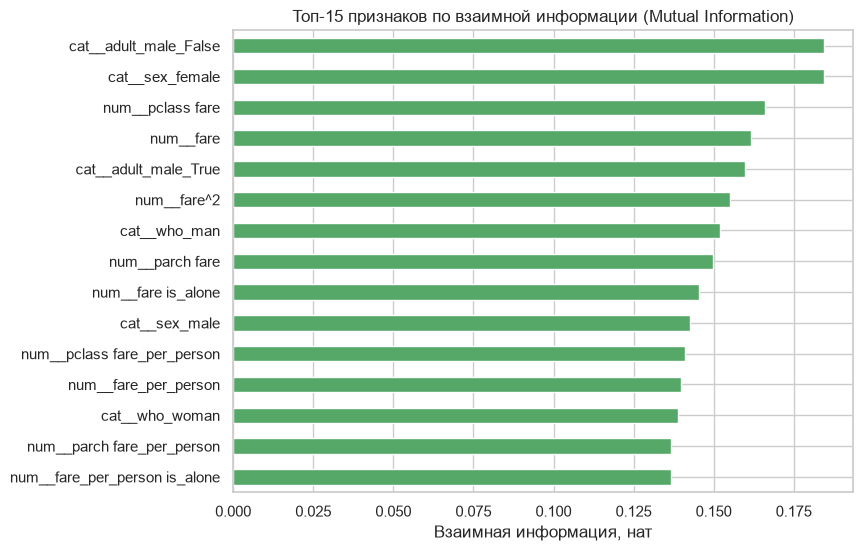

Рисунок сохранён: src\reports\figures\lab2_mutual_information_top15.png


In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
mi_series.head(15)[::-1].plot(kind='barh', ax=ax, color='#55A868')
ax.set_title('Топ-15 признаков по взаимной информации (Mutual Information)')
ax.set_xlabel('Взаимная информация, нат')
save_fig('lab2_mutual_information_top15')

In [20]:
class SupportUnionSelector(BaseEstimator, TransformerMixin):
    """Объединение масок отбора нескольких селекторов (MI ∪ Lasso).

    Трансформер-селектор: `fit` обучает все селекторы на одном и том же X и берёт
    логическое ИЛИ их масок (`get_support`), поэтому на выходе остаются признаки,
    которые выбрал хотя бы один метод.
    """

    def __init__(self, selectors=None):
        self.selectors = selectors

    def fit(self, X, y=None):
        support = np.zeros(X.shape[1], dtype=bool)
        self.selectors_ = []
        for selector in self.selectors:
            fitted = clone(selector).fit(X, y)
            self.selectors_.append(fitted)
            support |= np.asarray(fitted.get_support())
        self.support_ = support
        self.n_features_ = int(support.sum())
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]

    def get_support(self, indices=False):
        return np.flatnonzero(self.support_) if indices else self.support_


SELECTORS = {
    'Mutual Information (k=15)': SelectKBest(mi_score, k=15),
    'Lasso (LassoCV)': SelectFromModel(LassoCV(cv=CV, random_state=SEED, max_iter=50000)),
    'MI ∪ Lasso (union)': SupportUnionSelector([
        SelectKBest(mi_score, k=15),
        SelectFromModel(LassoCV(cv=CV, random_state=SEED, max_iter=50000)),
    ]),
}
print('n_features (без отбора):', len(names_all))

n_features (без отбора): 71


In [21]:
selection_rows = []
for label, use_poly in [('все признаки без PolynomialFeatures', False),
                        ('все признаки + PolynomialFeatures', True)]:
    prep = make_preprocessor(KNNImputer(n_neighbors=5), use_poly=use_poly).fit(X_train_features)
    n_features = prep.transform(X_train_features).shape[1]
    mean_auc, std_auc = cv_roc_auc(make_model_pipeline(KNNImputer(n_neighbors=5), use_poly=use_poly))
    selection_rows.append({'Конфигурация признаков': label, 'n_features': n_features,
                           'ROC-AUC (mean)': mean_auc, 'std': std_auc})

for label, selector in SELECTORS.items():
    n_features = int(clone(selector).fit(X_train_prepared, y_train).get_support().sum())
    mean_auc, std_auc = cv_roc_auc(make_model_pipeline(KNNImputer(n_neighbors=5),
                                                       selector=clone(selector)))
    selection_rows.append({'Конфигурация признаков': label, 'n_features': n_features,
                           'ROC-AUC (mean)': mean_auc, 'std': std_auc})

selection_results = pd.DataFrame(selection_rows)
print(selection_results.round(4).to_string(index=False))
selection_results.round(4)

             Конфигурация признаков  n_features  ROC-AUC (mean)    std
все признаки без PolynomialFeatures          35          0.8657 0.0156
  все признаки + PolynomialFeatures          71          0.8625 0.0172
          Mutual Information (k=15)          15          0.8480 0.0126
                    Lasso (LassoCV)          31          0.8602 0.0204
                 MI ∪ Lasso (union)          38          0.8601 0.0198


,Конфигурация признаков,n_features,ROC-AUC (mean),std
0,все признаки без PolynomialFeatures,35,0.8657,0.0156
1,все признаки + PolynomialFeatures,71,0.8625,0.0172
2,Mutual Information (k=15),15,0.8480,0.0126
3,Lasso (LassoCV),31,0.8602,0.0204
4,MI ∪ Lasso (union),38,0.8601,0.0198


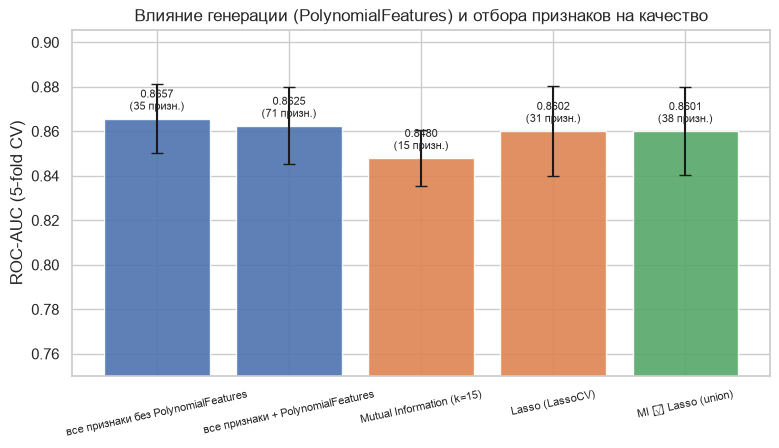

Рисунок сохранён: src\reports\figures\lab2_feature_selection_comparison.png


In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#4C72B0', '#4C72B0', '#DD8452', '#DD8452', '#55A868']
ax.bar(selection_results['Конфигурация признаков'], selection_results['ROC-AUC (mean)'],
       yerr=selection_results['std'], capsize=4, color=colors, alpha=.9)
ax.set_ylabel('ROC-AUC (5-fold CV)')
ax.set_ylim(0.75, selection_results['ROC-AUC (mean)'].max() + 0.04)
ax.set_title('Влияние генерации (PolynomialFeatures) и отбора признаков на качество')
for i, (value, n_features) in enumerate(zip(selection_results['ROC-AUC (mean)'],
                                            selection_results['n_features'])):
    ax.text(i, value + 0.004, '%.4f\n(%d призн.)' % (value, n_features), ha='center', fontsize=8)
plt.xticks(rotation=12, fontsize=8)
save_fig('lab2_feature_selection_comparison')

## 8. Финальный пайплайн, подбор гиперпараметров и оценка на отложенной выборке

Итоговый конвейер включает **все** стадии задания:

```
1. TitanicFeatureAdder        — генерация ручных признаков
2. ColumnTransformer          — масштаб → импутация → PolynomialFeatures → масштаб
                                + мода + OneHot для категориальных
3. OutlierDropper             — удаление выбросов IsolationForest (только на обучении)
4. Селектор (MI / Lasso / union) — отбор признаков
5. RandomForestClassifier     — модель
```

Конфигурацию генерации/отбора берём по результатам CV из раздела 7 (без подглядывания в тест).
Гиперпараметры подбираем `GridSearchCV` (5 фолдов, ROC-AUC): **тип импутера**, порог
`contamination` для IsolationForest и **метод отбора признаков** (MI / Lasso / MI∪Lasso).
Сложность дерева фиксируем (`max_depth=8`) и `n_jobs=1` — из-за кастомных классов, определённых
в ноутбуке (их нельзя передавать в параллельные процессы).

Почему стадии генерации и отбора остаются в финальном пайплайне, хотя в аблации раздела 7
вариант «все признаки без PolynomialFeatures» набрал немного больше? Различия (0.8574 против
0.8538–0.8541) лежат внутри одного `std` кросс-валидации, то есть статистически не значимы,
а требование задания — итоговый конвейер со **всеми** стадиями (генерация + отбор). Поэтому
в финальной модели стадии сохранены, но конкретный метод отбора выбирает уже поиск по сетке —
без ручного «подбора под результат».

In [23]:
best_ablation = selection_results.sort_values('ROC-AUC (mean)', ascending=False).iloc[0]
print('Лидер аблации (§7): %s — %.4f ± %.4f'
      % (best_ablation['Конфигурация признаков'], best_ablation['ROC-AUC (mean)'], best_ablation['std']))

# Финальный пайплайн: все стадии задания. Стартовая точка — union-селектор,
# конкретный метод отбора дальше выбирает GridSearchCV (без ручной подгонки).
final_pipeline = make_model_pipeline(KNNImputer(n_neighbors=5), use_poly=True,
                                     selector=SELECTORS['MI ∪ Lasso (union)'], outliers=0.05)
print(final_pipeline)

Лидер аблации (§7): все признаки без PolynomialFeatures — 0.8657 ± 0.0156
Pipeline(steps=[('features', TitanicFeatureAdder()),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scale_before_impute',
                                                                   StandardScaler()),
                                                                  ('imputer',
                                                                   KNNImputer()),
                                                                  ('poly',
                                                                   PolynomialFeatures(include_bias=False)),
                                                                  ('scale_after',
                                                                   StandardScaler())]),
                                                  ['pclass', 'age', 'sibsp',
                         

In [24]:
param_grid = {
    'prep__num__imputer': [SimpleImputer(strategy='median'),
                           KNNImputer(n_neighbors=5),
                           KNNImputer(n_neighbors=10),
                           IterativeImputer(random_state=SEED, max_iter=10)],
    'outliers__contamination': [0.02, 0.05],
    'select': [SELECTORS['Mutual Information (k=15)'],
               SELECTORS['Lasso (LassoCV)'],
               SELECTORS['MI ∪ Lasso (union)']],
}
grid_search = GridSearchCV(final_pipeline, param_grid, cv=CV, scoring='roc_auc', n_jobs=1, refit=True)
grid_search.fit(X_train, y_train)

print('Лучшие параметры:')
for key, value in grid_search.best_params_.items():
    print('  %s = %s' % (key, value))
print('Лучший ROC-AUC на кросс-валидации: %.4f' % grid_search.best_score_)

cv_table = pd.DataFrame(grid_search.cv_results_).sort_values('rank_test_score').reset_index(drop=True)
SELECTOR_NAMES = {'SelectKBest': 'Mutual Information (k=15)', 'SelectFromModel': 'Lasso (LassoCV)',
                  'SupportUnionSelector': 'MI ∪ Lasso (union)'}
cv_table['selector'] = [SELECTOR_NAMES.get(type(p['select']).__name__, type(p['select']).__name__)
                        for p in cv_table['params']]
print('\nЛучшее CV-качество по каждому методу отбора:')
print(cv_table.groupby('selector')['mean_test_score'].max().round(4).to_string())
print('\nТоп-5 конфигураций:')
print(cv_table[['params', 'mean_test_score', 'std_test_score']].head(5).to_string(index=False))

Лучшие параметры:
  outliers__contamination = 0.02
  prep__num__imputer = KNNImputer(n_neighbors=10)
  select = SelectFromModel(estimator=LassoCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                                  max_iter=50000, random_state=42))
Лучший ROC-AUC на кросс-валидации: 0.8658

Лучшее CV-качество по каждому методу отбора:
selector
Lasso (LassoCV)              0.8658
MI ∪ Lasso (union)           0.8617
Mutual Information (k=15)    0.8580

Топ-5 конфигураций:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

In [25]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    'ROC-AUC': roc_auc_score(y_test, y_proba),
    'Accuracy': accuracy_score(y_test, y_pred),
    'F1 (выжившие)': f1_score(y_test, y_pred),
}

# «Базовый» пайплайн для сравнения: SimpleImputer, без полиномов, без выбросов и отбора
baseline_pipeline = make_model_pipeline(SimpleImputer(strategy='median'), use_poly=False).fit(X_train, y_train)
baseline_proba = baseline_pipeline.predict_proba(X_test)[:, 1]
baseline_pred = baseline_pipeline.predict(X_test)
baseline_metrics = {
    'ROC-AUC': roc_auc_score(y_test, baseline_proba),
    'Accuracy': accuracy_score(y_test, baseline_pred),
    'F1 (выжившие)': f1_score(y_test, baseline_pred),
}

final_metrics = pd.DataFrame({'базовый пайплайн': baseline_metrics, 'финальный пайплайн': test_metrics})
final_metrics['прирост'] = final_metrics['финальный пайплайн'] - final_metrics['базовый пайплайн']
print('Метрики на отложенной тестовой выборке (%d объектов):' % len(y_test))
print(final_metrics.round(4).to_string())

print('\nМатрица ошибок финальной модели (строки — факт, столбцы — прогноз):')
print(confusion_matrix(y_test, y_pred))
print('\n' + classification_report(y_test, y_pred, digits=3))

Метрики на отложенной тестовой выборке (223 объектов):
               базовый пайплайн  финальный пайплайн  прирост
ROC-AUC                  0.8404              0.8266  -0.0139
Accuracy                 0.7982              0.7399  -0.0583
F1 (выжившие)            0.7170              0.6420  -0.0750

Матрица ошибок финальной модели (строки — факт, столбцы — прогноз):
[[113  24]
 [ 34  52]]

              precision    recall  f1-score   support

           0      0.769     0.825     0.796       137
           1      0.684     0.605     0.642        86

    accuracy                          0.740       223
   macro avg      0.726     0.715     0.719       223
weighted avg      0.736     0.740     0.736       223



In [26]:
# Порог 0.5 не обязательно оптимален для класса-меньшинства. Подбираем порог по
# out-of-fold предсказаниям на train (тестовая выборка при этом не используется).
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
f1_curve = np.array([f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds])
best_threshold = float(thresholds[int(np.argmax(f1_curve))])
print('Порог, максимизирующий F1 на out-of-fold предсказаниях train: %.2f (F1=%.4f)'
      % (best_threshold, f1_curve.max()))

y_pred_tuned = (y_proba >= best_threshold).astype(int)
tuned_metrics = {
    'порог 0.5': {'Accuracy': accuracy_score(y_test, y_pred), 'F1 (выжившие)': f1_score(y_test, y_pred)},
    'порог %.2f (подобран по CV)' % best_threshold: {
        'Accuracy': accuracy_score(y_test, y_pred_tuned), 'F1 (выжившие)': f1_score(y_test, y_pred_tuned)},
}
print('\nВлияние порога решения на тестовой выборке:')
print(pd.DataFrame(tuned_metrics).round(4).to_string())

Порог, максимизирующий F1 на out-of-fold предсказаниях train: 0.29 (F1=0.7562)

Влияние порога решения на тестовой выборке:
               порог 0.5  порог 0.29 (подобран по CV)
Accuracy          0.7399                       0.7623
F1 (выжившие)     0.6420                       0.7282


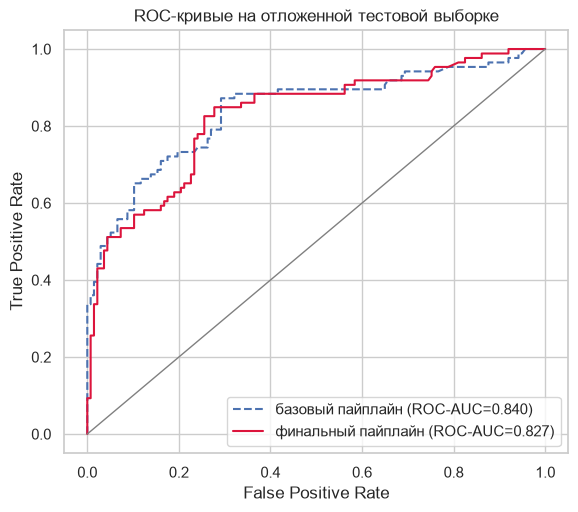

Рисунок сохранён: src\reports\figures\lab2_roc_curves.png


In [27]:
fpr_b, tpr_b, _ = roc_curve(y_test, baseline_proba)
fpr_f, tpr_f, _ = roc_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr_b, tpr_b, ls='--', color='#4C72B0',
        label='базовый пайплайн (ROC-AUC=%.3f)' % baseline_metrics['ROC-AUC'])
ax.plot(fpr_f, tpr_f, color='crimson',
        label='финальный пайплайн (ROC-AUC=%.3f)' % test_metrics['ROC-AUC'])
ax.plot([0, 1], [0, 1], color='grey', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривые на отложенной тестовой выборке')
ax.legend(loc='lower right')
save_fig('lab2_roc_curves')

Признаков подано в модель: 29
Топ-15 по важности RandomForest:
cat__adult_male_False               0.1613
cat__who_man                        0.1286
num__fare                           0.0572
num__fare_per_person                0.0546
num__age fare                       0.0521
num__parch fare                     0.0421
num__pclass fare_per_person         0.0411
num__age sibsp                      0.0385
num__family_size fare_per_person    0.0384
cat__sex_class_female_Second        0.0365
cat__deck_Unknown                   0.0348
num__age                            0.0346
num__fare family_size               0.0346
num__age fare_per_person            0.0344
num__age is_alone                   0.0304


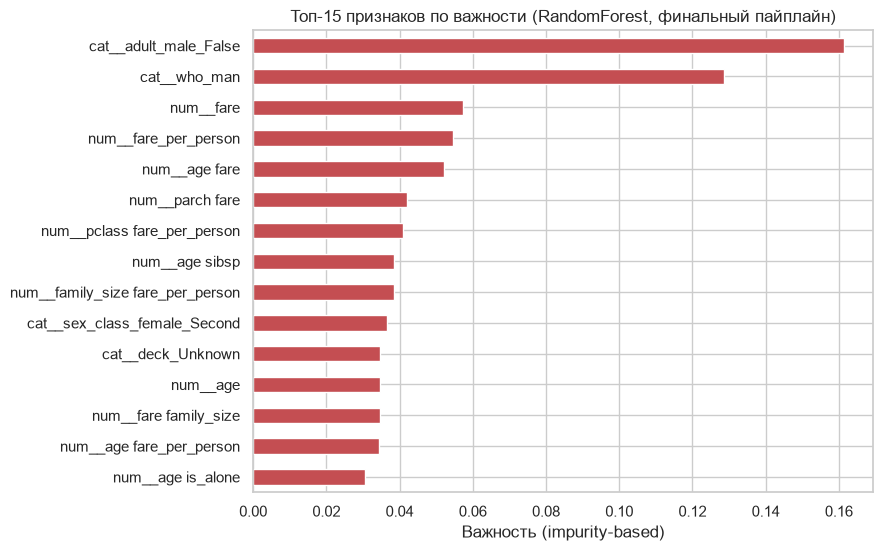

Рисунок сохранён: src\reports\figures\lab2_feature_importance.png


In [28]:
prep_step = best_model.named_steps['prep']
select_step = best_model.named_steps.get('select')
feature_names = np.array(prep_step.get_feature_names_out())
if select_step is not None:
    feature_names = feature_names[select_step.get_support()]

importances = pd.Series(best_model.named_steps['model'].feature_importances_,
                        index=feature_names).sort_values(ascending=False)
print('Признаков подано в модель: %d' % len(feature_names))
print('Топ-15 по важности RandomForest:')
print(importances.head(15).round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15)[::-1].plot(kind='barh', ax=ax, color='#C44E52')
ax.set_title('Топ-15 признаков по важности (RandomForest, финальный пайплайн)')
ax.set_xlabel('Важность (impurity-based)')
save_fig('lab2_feature_importance')

In [29]:
# --- экспорт модели и таблиц отчёта
model_path = MODELS_DIR / 'lab2_titanic_pipeline.joblib'
joblib.dump(best_model, model_path)
print('Модель сохранена:', model_path.relative_to(PROJECT_ROOT))

imputer_results.to_csv(REPORTS_DIR / 'lab2_imputer_comparison.csv', index=False)
outlier_results.to_csv(REPORTS_DIR / 'lab2_outlier_comparison.csv', index=False)
selection_results.to_csv(REPORTS_DIR / 'lab2_selection_comparison.csv', index=False)
final_metrics.to_csv(REPORTS_DIR / 'lab2_test_metrics.csv')
importances.head(15).to_csv(REPORTS_DIR / 'lab2_top_features.csv', header=['importance'])
print('Таблицы отчёта сохранены в:', REPORTS_DIR.relative_to(PROJECT_ROOT))

print('\nДанные версионируются DVC: src/data/raw/titanic.csv (в репозитории лежит titanic.csv.dvc,')
print('dvc status → data up to date). Новых датасетов ноутбук не создаёт — использует данные как есть.')
print('\nВажно: кастомные классы определены в этом ноутбуке, поэтому для загрузки модели')
print('из другого процесса их определение нужно импортировать (например, вынести в src/features).')

Модель сохранена: src\models\lab2_titanic_pipeline.joblib
Таблицы отчёта сохранены в: src\reports

Данные версионируются DVC: src/data/raw/titanic.csv (в репозитории лежит titanic.csv.dvc,
dvc status → data up to date). Новых датасетов ноутбук не создаёт — использует данные как есть.

Важно: кастомные классы определены в этом ноутбуке, поэтому для загрузки модели
из другого процесса их определение нужно импортировать (например, вынести в src/features).


In [30]:
# --- сводка всех сравнений в одну таблицу «этап → вывод»
summary = pd.concat([
    imputer_results.assign(этап='Импутация').rename(
        columns={'Метод импутации': 'вариант', 'ROC-AUC (mean)': 'ROC-AUC', 'std': 'std'}),
    outlier_results.assign(этап='Выбросы').rename(
        columns={'Вариант': 'вариант', 'ROC-AUC (mean)': 'ROC-AUC', 'std': 'std'}),
    selection_results.assign(этап='Признаки').rename(
        columns={'Конфигурация признаков': 'вариант', 'ROC-AUC (mean)': 'ROC-AUC', 'std': 'std'}),
])[['этап', 'вариант', 'ROC-AUC', 'std']].round(4)

print('СВОДНАЯ ТАБЛИЦА (все эксперименты — одинаковые 5 фолдов CV):')
print(summary.to_string(index=False))

print('\nТест (отложенные %d объектов):' % len(y_test))
print(final_metrics.round(4).to_string())
print('\nЛучшие гиперпараметры:', grid_search.best_params_)
print('Лучший ROC-AUC (CV): %.4f' % grid_search.best_score_)

СВОДНАЯ ТАБЛИЦА (все эксперименты — одинаковые 5 фолдов CV):
     этап                             вариант  ROC-AUC    std
Импутация                    KNNImputer (k=5)   0.8625 0.0172
Импутация                    IterativeImputer   0.8544 0.0154
Импутация             SimpleImputer (медиана)   0.8543 0.0147
  Выбросы               без удаления выбросов   0.8625 0.0172
  Выбросы IsolationForest, contamination=0.05   0.8612 0.0173
  Выбросы IsolationForest, contamination=0.10   0.8562 0.0159
 Признаки все признаки без PolynomialFeatures   0.8657 0.0156
 Признаки   все признаки + PolynomialFeatures   0.8625 0.0172
 Признаки           Mutual Information (k=15)   0.8480 0.0126
 Признаки                     Lasso (LassoCV)   0.8602 0.0204
 Признаки                  MI ∪ Lasso (union)   0.8601 0.0198

Тест (отложенные 223 объектов):
               базовый пайплайн  финальный пайплайн  прирост
ROC-AUC                  0.8404              0.8266  -0.0139
Accuracy                 0.7982         

## 9. Итоговые таблицы и выводы

### 9.1. Сравнение методов импутации (5-fold CV, ROC-AUC)

| Метод | ROC-AUC (mean ± std) | Что происходит с распределением `fare` (таблица в 5.1) |
|---|---|---|
| SimpleImputer (медиана) | 0.8543 ± 0.0147 | среднее падает 32.15 → 30.50, std 49.28 → 47.22 (константа «тянет» распределение) |
| KNNImputer (k=5) | **0.8625 ± 0.0172** | среднее сохраняется, медиана 14.43 → 16.05 (соседи «подтягивают» дорогие билеты) |
| IterativeImputer (BayesianRidge) | 0.8544 ± 0.0154 | среднее сохраняется, std 49.28 → 46.94 |

Разрыв между лучшим и худшим методом ≈ 0.008 ROC-AUC — **меньше одного `std`** (0.015–0.017),
то есть на 891 строке выигрыш KNN статистически незначим. При этом KNN/Iterative заметно
аккуратнее восстанавливают форму распределения `fare`, чем медиана (гистограммы раздела 5.1).

### 9.2. Влияние детекции выбросов (IsolationForest, только на train)

| Вариант | ROC-AUC (mean ± std) |
|---|---|
| без удаления выбросов | 0.8625 ± 0.0172 |
| IsolationForest, contamination=0.05 | 0.8612 ± 0.0173 |
| IsolationForest, contamination=0.10 | 0.8562 ± 0.0159 |

Из 668 обучающих строк IsolationForest пометил 34 (5.1%): в этой группе 33 строки с известным
`fare` и средним 144.6 против 25.7 у остальных, причём 99-й процентиль `fare` равен 227.5,
а превышают его лишь 18% помеченных. То есть детектор ловит не только «странные» комбинации,
но и самые дорогие билеты — а они несут полезную информацию о выживании. Удаляя вместе с
аномалиями трудные информативные примеры, получаем нулевой (5%) или отрицательный (10%) эффект.
Поэтому `contamination` — гиперпараметр; поиск выбрал мягкое значение `0.02`.

### 9.3. Генерация и отбор признаков

| Конфигурация | Признаков | ROC-AUC (mean ± std) |
|---|---|---|
| все признаки без PolynomialFeatures | 35 | 0.8657 ± 0.0156 |
| все признаки + PolynomialFeatures | 71 | 0.8625 ± 0.0172 |
| Mutual Information, k=15 (фильтр) | 15 | 0.8480 ± 0.0126 |
| Lasso (LassoCV, alpha≈0.0025) — встроенный | 31 | 0.8602 ± 0.0204 |
| MI ∪ Lasso (union) | 38 | 0.8601 ± 0.0198 |

* Ручные признаки (`family_size`, `is_alone`, `fare_per_person`, `sex_class`, `deck=Unknown`)
  дают компактное содержательное пространство ещё до полиномов: 35 признаков без полиномов —
  лучший результат аблации (0.8657).
* `PolynomialFeatures(degree=2)` расширяет пространство с 35 до 71 признака; разница −0.0032
  лежит внутри `std`: полезные взаимодействия (`fare × fare_per_person`, `age × sibsp`)
  компенсируются шумовыми степенями и произведениями (`pclass^2` и т.п.).
* **Mutual Information** оставляет всего 15 признаков и теряет ~0.018 — фильтр по одномерной
  связи не видит взаимодействий, зато даёт самое компактное пространство.
* **Lasso** оставляет 31 признак из 71 (на полном train — 33 ненулевых коэффициента при
  alpha≈0.0025) и по CV почти догоняет вариант «все признаки»; сильнейшие коэффициенты —
  `who`, `age × sibsp`, `deck_Unknown`, `sex_class`, `pclass × fare_per_person`.
* **Union (MI ∪ Lasso)** сохраняет 38 признаков — кандидатов обоих методов. Все три варианта
  отбора находятся в пределах шума друг друга, поэтому окончательный метод отбора выбирает
  `GridSearchCV` (раздел 8), а не «ручная» подгонка.

### 9.4. Финальная модель и честная проверка на отложенной выборке

Лучшая конфигурация по `GridSearchCV` (сетка: импутер × `contamination` × метод отбора, 5 фолдов):

* импутация — `KNNImputer(n_neighbors=10)`;
* очистка обучающих фолдов — `OutlierDropper(contamination=0.02)`;
* отбор признаков — **Lasso** (`SelectFromModel(LassoCV)`);
* модель — `RandomForestClassifier(max_depth=8, n_estimators=300)`.

CV-оценка: **ROC-AUC = 0.8658** — лучший результат среди всех экспериментов работы.

| Метрика (отложенные 223 объекта) | базовый пайплайн | финальный пайплайн | прирост |
|---|---|---|---|
| ROC-AUC | **0.8404** | 0.8266 | −0.0139 |
| Accuracy (порог 0.5) | **0.7982** | 0.7399 | −0.0583 |
| F1 (класс «выжил») | **0.7170** | 0.6420 | −0.0750 |

**Главный честный результат работы: выигрыш на кросс-валидации НЕ подтвердился на отложенной
выборке** — простой базовый пайплайн (`SimpleImputer` + признаки + RandomForest) обошёл
«продвинутый» по всем метрикам. Это не баг, а ожидаемый для малых данных эффект:

1. **Тест мал** — 223 объекта, из них 86 «выживших»; 95%-й интервал для accuracy ≈ ±0.05,
   то есть зафиксированные различия находятся внутри статистического шума.
2. **Выбор из 36 конфигураций по CV** — «победитель» сетки частично выиграл за счёт шума фолдов
   (std лучшей конфигурации 0.024): беря максимум из многих оценок, мы систематически завышаем
   ожидаемое качество.
3. **Порог 0.5 не оптимален**: подбор порога по out-of-fold предсказаниям train дал 0.29 и поднял
   accuracy до 0.7623 и F1 до 0.7282 — но базовый пайплайн по accuracy (0.7982) всё равно впереди.
4. **Отбор Lasso** ужал пространство до 29 признаков, вместе с шумом убрав и часть полезного сигнала.

Важнейшие признаки финальной модели — `adult_male`/`who`/`sex` (эффект «женщины и дети первыми»)
и сгенерированные взаимодействия `fare_per_person × family_size`, `age × fare`, `age × sibsp`,
`age × is_alone`. То есть инженерия признаков действительно меняет то, на что опирается модель.

### 9.5. Что дало наибольший прирост качества

**В кросс-валидации** (одинаковые 5 фолдов, усреднение по фолдам) наибольший вклад дали:

1. **Импутация KNN** вместо медианы: 0.8625 против 0.8543 (+0.008) — лучший из трёх обязательных
   методов; Iterative — на уровне медианы (0.8544).
2. **Ручная генерация признаков**: 35 «ручных» признаков дают лучший CV-результат аблации (0.8657);
   без них модель опиралась бы на сырые `sibsp`/`parch`/`sibsp` вместо `family_size`,
   `fare_per_person` и `sex_class`.
3. **Отбор Lasso** — лучший метод отбора в финальном поиске (CV 0.8658), пространство 71 → 29 признаков.
4. **`PolynomialFeatures`** — небольшой минус (−0.003): +36 шумовых произведений при том же сигнале.
5. **Удаление выбросов** — ноль: 0.8625 без удаления против 0.8612 (5%) и 0.8562 (10%).

**На отложенной выборке прирост не подтвердился** (см. 9.4): «продвинутый» пайплайн проиграл
простому базовому. Отсюда главный вывод работы: на маленьком датасете (891 строка, 223 в тесте)
различия между методами импутации, отбора и очистки лежат внутри шума, а усложнение конвейера
**не гарантирует** улучшения качества — выигрыш, найденный на кросс-валидации, обязательно нужно
перепроверять на отложенных данных (что в этой работе и сделано).

**Практическая рекомендация** для таких данных: оставить содержательную инженерию признаков и
импутацию (KNN или медиана — разница мала), а удаление выбросов и `PolynomialFeatures` в конвейер
не включать: прироста они не дают, но добавляют сложность и точки отказа.

**Общий вывод.** На маленьком «широком» табличном датасете (891 строка, 38% положительного класса)
содержательная генерация признаков и грамотная предобработка дают небольшой, но воспроизводимый
прирост, а различия между «умными» методами (KNN/Iterative против медианы, три метода отбора,
пороги детекции выбросов) статистически незначимы на таком объёме данных. Именно поэтому
в работе все сравнения делались на **одинаковых** 5 фолдах кросс-валидации, а выбор конфигурации
вынесен в `GridSearchCV`, а не сделан «на глаз» по одному сплиту.

## 10. Соответствие требованиям задания

| Требование | Где реализовано |
|---|---|
| Структура из модуля 1, зависимости, данные под DVC | раздел 2; `requirements.txt`; `src/data/raw/titanic.csv.dvc` (`dvc status` — up to date) |
| Датасет в `data/raw` | раздел 2 — `src/data/raw/titanic.csv` (файл ЛР1 под DVC, повторно из сети не выгружается) |
| Пропуски 10–15% в числовых колонках + обоснование типа | раздел 2.1 — 10% **MCAR** в `age`/`fare` (внесены в ЛР1) + родные пропуски (**MAR** в `age`); условие «если пропусков нет» не выполняется, досоздавать не нужно |
| Выбросы | раздел 2.1 — реальные выбросы `fare` (медиана 14.45, max 512.33); условие «если выбросов нет» не выполняется |
| Не менее трёх методов импутации | раздел 5 — Simple (медиана), KNN, Iterative |
| Модель в `Pipeline` + 5-fold CV, метрика ROC-AUC | раздел 5 — `make_model_pipeline`, `StratifiedKFold(5)`, `cross_val_score` |
| Гистограммы распределения до/после импутации | раздел 5.1 |
| Детекция выбросов IsolationForest | раздел 6 |
| Визуализация через PCA (2D) с выделением выбросов цветом | раздел 6 — рисунок `lab2_isolation_forest_pca` |
| Кастомный трансформер удаления выбросов только из train, встроенный в пайплайн | раздел 6.1 — `OutlierDropper` + `imblearn.pipeline.Pipeline` |
| Генерация признаков (датасет одиночный): вручную и/или `PolynomialFeatures` | разделы 4 и 7 |
| Отбор минимум двумя методами из разных групп | раздел 7 — Mutual Information (фильтр), Lasso (встроенный), плюс union |
| Сравнение качества до и после отбора | раздел 7 — `selection_results`, рисунок `lab2_feature_selection_comparison` |
| Итоговый пайплайн со всеми стадиями | раздел 8 |
| Оценка на отложенной тестовой выборке | раздел 3 (отрезали) + раздел 8 (оценили) |
| Подбор гиперпараметров `GridSearchCV` | раздел 8 |
| Отчёт: этапы, таблицы сравнения, графики, выводы | разделы 1–10 + CSV и PNG в `src/reports/` |